In [ ]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



In [ ]:
df=pd.read_csv("/content/Advertising Budget and Sales.csv")
df.head()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
TV Ad Budget ($),0
Radio Ad Budget ($),0
Newspaper Ad Budget ($),0
Sales ($),0


In [ ]:
df.describe()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [ ]:
df.drop(columns=['Unnamed: 0'],inplace=True)

In [ ]:
df=df.rename(columns={"TV Ad Budget ($)": "TV","Radio Ad Budget ($)":"Radio","Newspaper Ad Budget ($)":"Newspaper","Sales ($)":"Sales"})

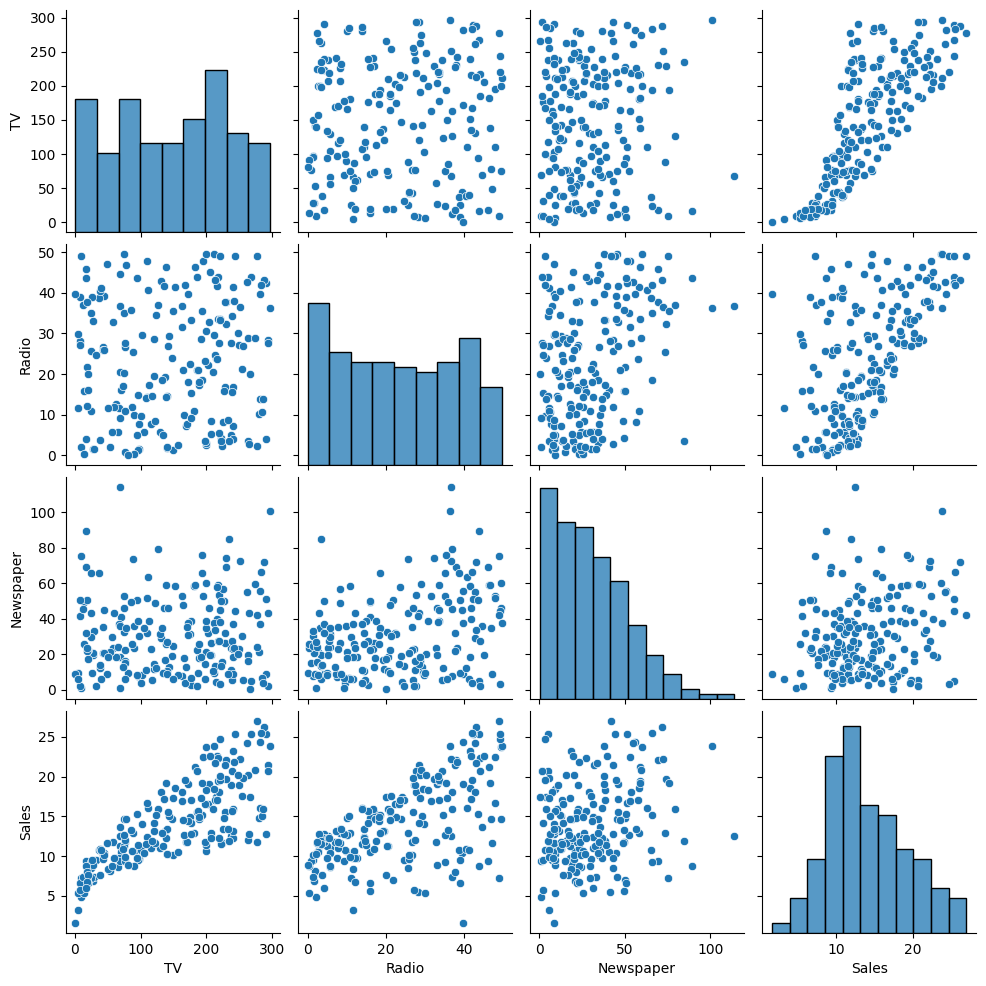

In [ ]:
sns.pairplot(df)
plt.show()


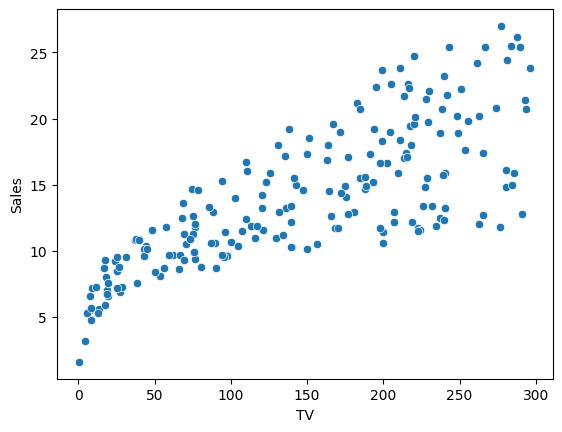

In [ ]:
sns.scatterplot(x="TV",y="Sales",data=df)
plt.show()


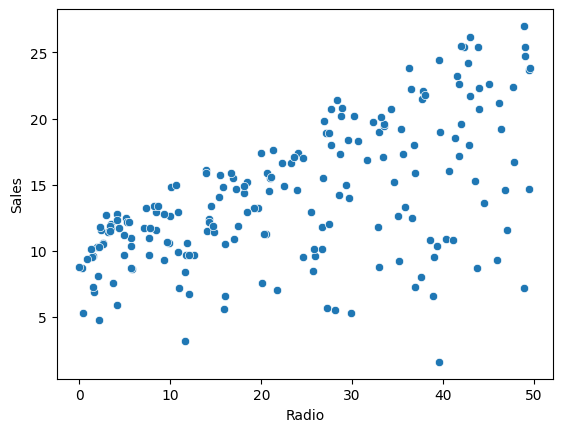

In [ ]:
sns.scatterplot(x="Radio",y="Sales",data=df)
plt.show()


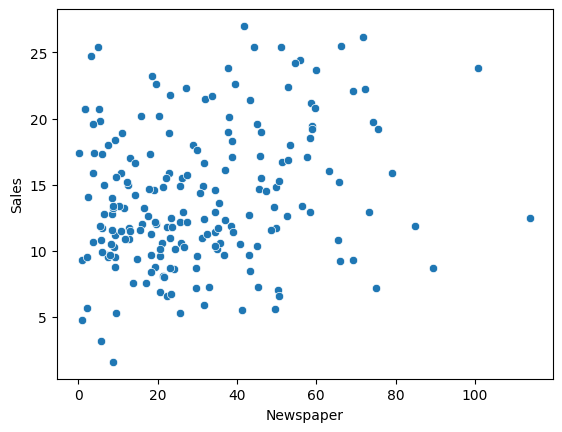

In [ ]:
sns.scatterplot(x="Newspaper",y="Sales",data=df)
plt.show()


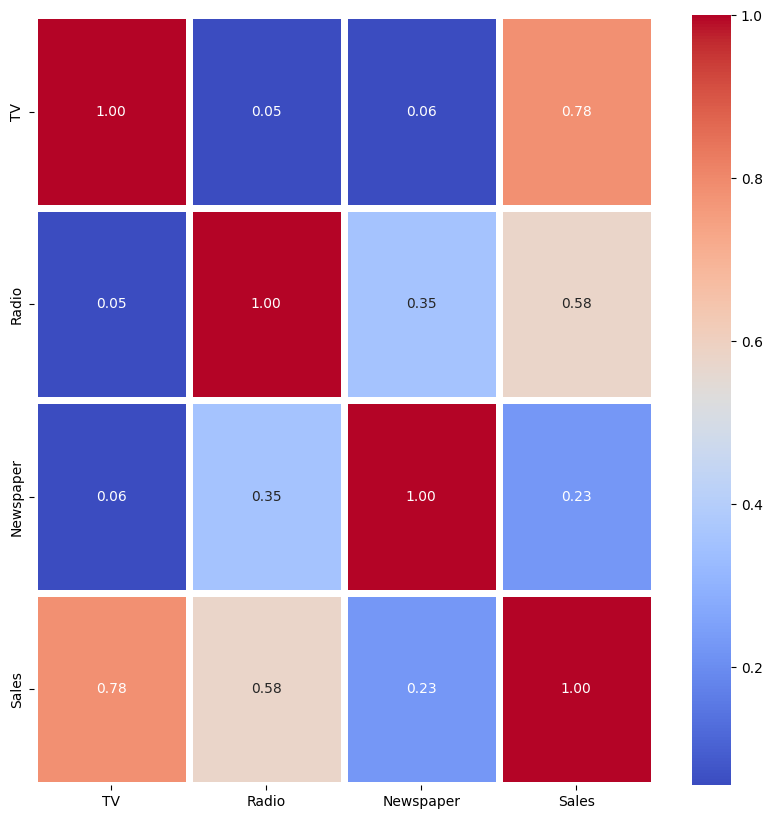

In [ ]:
corr=df.corr()
plt.figure(figsize=(10,10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=5)
plt.show()

In [ ]:
x=df.drop(columns=['Sales'])
y=df['Sales']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:

lr_model=LinearRegression()
lr_model.fit(x_train,y_train)
y_pred_lr=lr_model.predict(x_test)


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(x_train, y_train)
y_pred_poly = poly_model.predict(x_test)

In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_poly)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_poly)
    ]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Polynomial Regression,0.526179,0.642581,0.986918


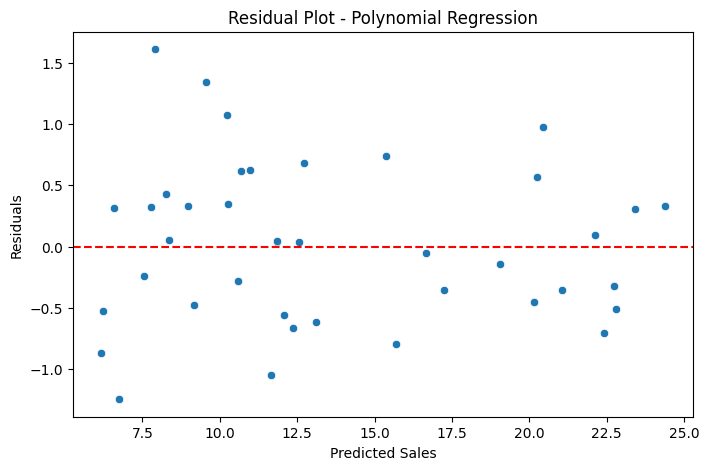

In [ ]:
# Calculate residuals for the best model
residuals = y_test - y_pred_poly

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred_poly, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot - Polynomial Regression")
plt.show()

This graph is called a Residual Plot for a polynomial regression model, and it shows the sales prediction errors. The red dashed line at zero represents a perfect prediction, while the scattered points show the model's accuracy. Since the points are randomly scattered above and below the zero line without a clear pattern, this indicates that the model performs well and fits the data appropriately.

In [ ]:
# Get the trained polynomial model steps
poly_features = poly_model.named_steps["polynomialfeatures"]
reg_features = poly_model.named_steps["linearregression"]

# Get the generated feature names
feature_names = poly_features.get_feature_names_out(x_train.columns)

# Display polynomial coefficients
poly_coefficients = pd.Series(
    reg_features.coef_,
    index=feature_names
)

print(poly_coefficients.sort_values(ascending=False))

TV                 0.053236
Radio              0.017098
Newspaper          0.010581
TV Radio           0.001111
Radio^2            0.000133
Radio Newspaper    0.000125
Newspaper^2        0.000028
TV Newspaper      -0.000074
TV^2              -0.000112
dtype: float64


Polynomial Regression Coefficients Interpretation:

TV has the largest positive coefficient among the individual features, followed by Radio and Newspaper. The model also considers squared terms and interactions between advertising channels to capture more complex relationships with sales.

In [ ]:
coefficients = pd.Series(
    lr_model.coef_,
    index=x_train.columns
)

coefficients = coefficients.sort_values(ascending=False)

print(coefficients)

Radio        0.189195
TV           0.044730
Newspaper    0.002761
dtype: float64




Linear Regression Coefficients Interpretation:

Radio has the largest positive coefficient (0.189), followed by TV (0.045) and Newspaper (0.003). This suggests that Radio advertising has the strongest positive relationship with sales, followed by TV, while Newspaper has a relatively small effect.

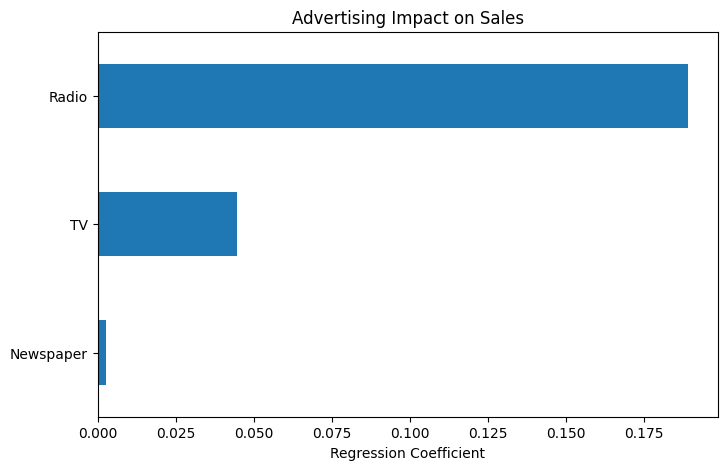

In [ ]:
coefficients.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Advertising Impact on Sales"
)

plt.xlabel("Regression Coefficient")
plt.show()

This bar chart shows the impact of different advertising channels on sales based on their regression coefficients. Radio advertising has the highest impact on sales, followed by TV, while Newspaper advertising has the lowest impact.